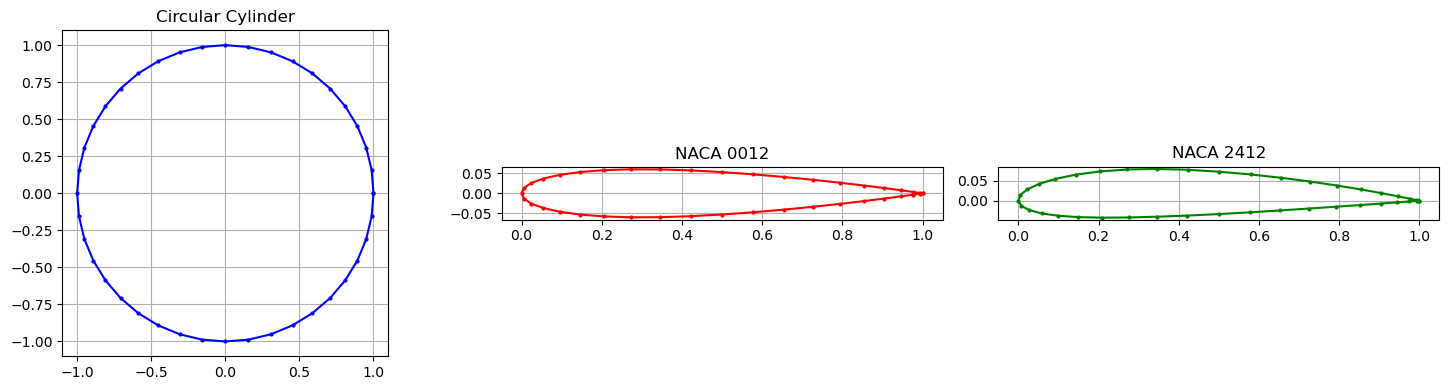

Geometry generation completed
--------------------------------
Number of panels: 40
Number of control points: 40
First panel length: 0.0062
First panel angle: 184.4256
First beta angle: 269.4256


In [1]:

# Vortex Panel Method - Geometry Generation

import numpy as np
import matplotlib.pyplot as plt


# 1. Numerical output formatting


def fmt(value, digits=4):
    value = float(value)

    if abs(value) < 0.5 * 10**(-digits):
        return "0"

    return f"{value:.{digits}f}".rstrip("0").rstrip(".")



# 2. Calculate panel geometry


def panel_geometry(XB, YB):

    dX = np.diff(XB)
    dY = np.diff(YB)

    # Panel length
    S = np.hypot(dX, dY)

    # Panel orientation angle
    phi = np.mod(np.arctan2(dY, dX), 2*np.pi)

    # Control point coordinates
    XC = 0.5 * (XB[:-1] + XB[1:])
    YC = 0.5 * (YB[:-1] + YB[1:])

    return XC, YC, S, phi



# 3. Calculate beta angle


def beta_angle(phi, alpha):

    beta = phi + np.pi/2 - alpha

    return beta


# 4. Generate circular cylinder coordinates


def cylinder_boundary_points(N, R=1.0):

    theta = np.linspace(0, -2*np.pi, N+1)

    XB = R * np.cos(theta)
    YB = R * np.sin(theta)

    return XB, YB



# 5. Generate NACA four-digit airfoil coordinates


def naca4_boundary_points(code, N, spacing='cosine'):

    if len(code) != 4 or not code.isdigit():
        raise ValueError("Enter a valid four-digit NACA code")

    if N < 4 or N % 2 != 0:
        raise ValueError("N must be an even number of at least 4")

    # Read NACA parameters
    m = int(code[0]) / 100
    p = int(code[1]) / 10
    t = int(code[2:]) / 100

    # Chordwise coordinate distribution
    n_side = N // 2

    if spacing == 'cosine':

        theta = np.linspace(0, np.pi, n_side+1)
        x = 0.5 * (1 - np.cos(theta))

    elif spacing == 'uniform':

        x = np.linspace(0, 1, n_side+1)

    else:

        raise ValueError("Spacing must be cosine or uniform")

    # Thickness distribution
    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1036*x**4
    )

    # Mean camber line
    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    if m != 0:

        for i in range(len(x)):

            if x[i] < p:

                yc[i] = (m/p**2) * (
                    2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/p**2
                ) * (p-x[i])

            else:

                yc[i] = (m/(1-p)**2) * (
                    (1-2*p) + 2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/(1-p)**2
                ) * (p-x[i])

    # Camber line angle
    theta_c = np.arctan(dyc_dx)

    # Upper surface coordinates
    xu = x - yt*np.sin(theta_c)
    yu = yc + yt*np.cos(theta_c)

    # Lower surface coordinates
    xl = x + yt*np.sin(theta_c)
    yl = yc - yt*np.cos(theta_c)

    # Arrange coordinates clockwise:
    # Trailing edge -> Lower surface -> Leading edge
    # -> Upper surface -> Trailing edge

    XB = np.concatenate((xl[::-1], xu[1:]))
    YB = np.concatenate((yl[::-1], yu[1:]))

    return XB, YB



# 6. Test the geometry functions


N = 40

# Cylinder
XB_cyl, YB_cyl = cylinder_boundary_points(N)

# NACA 0012
XB_0012, YB_0012 = naca4_boundary_points(
    '0012', N, spacing='cosine'
)

# NACA 2412
XB_2412, YB_2412 = naca4_boundary_points(
    '2412', N, spacing='cosine'
)



# 7. Plot generated geometries


fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(XB_cyl, YB_cyl, 'b-o', markersize=2)
ax[0].set_title('Circular Cylinder')
ax[0].set_aspect('equal')
ax[0].grid()

ax[1].plot(XB_0012, YB_0012, 'r-o', markersize=2)
ax[1].set_title('NACA 0012')
ax[1].set_aspect('equal')
ax[1].grid()

ax[2].plot(XB_2412, YB_2412, 'g-o', markersize=2)
ax[2].set_title('NACA 2412')
ax[2].set_aspect('equal')
ax[2].grid()

plt.tight_layout()
plt.show()



# 8. Check panel geometry


XC, YC, S, phi = panel_geometry(
    XB_2412, YB_2412
)

alpha = np.radians(5)

beta = beta_angle(phi, alpha)

print("Geometry generation completed")
print("--------------------------------")
print("Number of panels:", len(S))
print("Number of control points:", len(XC))
print("First panel length:", fmt(S[0]))
print("First panel angle:", fmt(np.degrees(phi[0])))
print("First beta angle:", fmt(np.degrees(beta[0])))
